# Growing Gaps

**Question:** How does the cost of returning to a teacher grow with the time since it was last seen?

Two fixed teachers each map 21 independent ±1 inputs through 10 LTUs to 10 linear outputs. Teacher weights are ±1 and every target has independent Gaussian noise of standard deviation 1. Training alternates between the two teachers: the first turn lasts 5k examples, each later turn is 10% longer than the one before (rounded to 1k examples), and training stops after 2M examples. All tasks share input and output coordinates; no task ID is supplied.

The learner has **21 inputs → 20 LTUs → 10 linear outputs**, enough features for both teachers. Weights, optimizer state, and centering statistics persist across switches. All biases are weights on constant-1 inputs. Predictions are scored before learning each target.

Compare five SGD step sizes and network Autostep, using the same five seeds for every configuration. SGD uses fan-in initialization and sigmoid surrogate derivatives. Autostep uses **meta step 0.02, initial ln(α) = −8**, hidden weights uniform in ±α₀, and uncompensated activation/derivative centering (rate 1e-3). Readouts start at zero. Autostep uses the `squared_inputs` implementation from the network Autostep notebooks, with normalization time constant 1e4.

**Privileged reference:** a shared linear Autostep readout of all 20 fixed, true teacher features, centered at 0.5. It receives neither the active task ID nor correct output weights, so it too must relearn its readout after every switch, but it cannot lose features.

Methods share teachers, switches, inputs and noise for matching seed IDs. The plots show the learning curves of the whole run, split into four parts of about ten turns each. They compare the SGD step size with the lowest mean per-seed RMSE over the whole run against Autostep and the ideal-feature baseline.

In [8]:
from functools import partial
from pathlib import Path
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

In [9]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS = 2
N_HIDDEN = 2 * WIDTH  # capacity for both teachers

# Autostep: uncompensated centering and small hidden initialization.
INIT_RATE, META_RATE, EMA_RATE = np.exp(-8.), 0.02, 1e-3

# Training
STEPS = 4_000_000
FIRST_TURN, GROWTH = 10_000, 1.2  # each turn on a teacher is GROWTH times longer than the one before
WINDOW = 1000
SGD_EXPONENTS = (-9, -8, -7, -6, -5)
SGD_RATES = [2.**p for p in SGD_EXPONENTS]
N_SEEDS = 5

# Turn lengths in windows, and the turn of every window.
turns = []
while sum(turns) < STEPS // WINDOW:
    turns.append(round(FIRST_TURN * GROWTH ** len(turns) / WINDOW))
TURN = np.repeat(np.arange(len(turns)), turns)[:STEPS // WINDOW]
assert STEPS % WINDOW == 0

## Task

In [10]:
def init_teacher(key):
    input_key, _, output_key = jax.random.split(key, 3)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > 0).astype(jnp.float32)

## Learner

In [11]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True,
                       tau=1e4, version='squared_inputs')

class Learner(NamedTuple):
    weights: tuple
    opt: object
    means: tuple
    slopes: tuple


def init_learner(key, widths, method):
    weights = []
    fan_in = N_INPUTS
    for width, subkey in zip(widths, jax.random.split(key, len(widths))):
        bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / fan_in)
        w = jax.random.uniform(subkey, (width, fan_in + 1), minval=-bound, maxval=bound)
        weights.append(w.at[:, -1].set(0.))
        fan_in = width
    weights.append(jnp.zeros((N_OUTPUTS, fan_in + 1)))
    weights = tuple(weights)
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   tuple(jnp.full(w.shape[0], .5) for w in weights[:-1]),
                   tuple(jnp.zeros_like(w).at[:, -1].set(.25) for w in weights[:-1]))


def forward(weights, x, learner, method):
    sources, means, slopes = [], [], []
    for w, mean, slope in zip(weights[:-1], learner.means, learner.slopes):
        source = jnp.append(x, 1.)
        sources.append(source[None])
        z = w @ source
        x = ltu(z)
        if method == 'Autostep':
            # Same uncompensated centering and centered surrogate as network_autostep.
            mean = mean + EMA_RATE * (jax.lax.stop_gradient(x) - mean)
            sigmoid = jax.nn.sigmoid(z)
            derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))
            slope = slope + EMA_RATE * (derivative[:, None] * jax.lax.stop_gradient(source) - slope)
            correction = jnp.sum(slope * w, axis=1)
            x = x - mean + (jax.lax.stop_gradient(correction) - correction)
        means.append(mean)
        slopes.append(slope)
    sources.append(jnp.append(x, 1.)[None])
    return weights[-1] @ sources[-1][0], (tuple(sources), tuple(means), tuple(slopes))


def update(learner, x, y, method, rate):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, method)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, means, slopes)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -rate * g, grads), None
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, means, slopes), 2 * loss_value / N_OUTPUTS

## Training

In [12]:
def train(seed, rate, method, reference=False):
    teacher_key, learner_key, schedule_key, rng = jax.random.split(jax.random.PRNGKey(seed), 4)
    teachers = jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))
    if reference:
        weights = (jnp.zeros((N_OUTPUTS, N_TASKS * WIDTH + 1)),)
        learner = Learner(weights, OPTIMIZER.init(weights), (), ())
    else:
        learner = init_learner(learner_key, (N_HIDDEN,), method)
    # Alternate teachers every turn, starting from a random one.
    tasks = (jax.random.randint(schedule_key, (), 0, N_TASKS) + jnp.asarray(TURN)) % N_TASKS

    def record(carry, task_id):
        teacher = jax.tree.map(lambda w: w[task_id], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            if reference:
                # All true features, with no indication of which task is active.
                x = (jnp.einsum('thi,i->th', teachers[0], x) > 0).astype(jnp.float32).reshape(-1) - .5
            learner, mse = update(learner, x, y, method, rate)
            return (learner, rng), mse

        # Window means of the MSE.
        carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
        return carry, mse.mean()

    _, mse = jax.lax.scan(record, (learner, rng), tasks)
    return mse


@partial(jax.jit, static_argnames=('method', 'reference'))
def train_many(seeds, rates, method, reference=False):
    one = partial(train, method=method, reference=reference)
    # Inner vmap: seeds; outer vmap: step sizes.
    return jax.vmap(jax.vmap(one, in_axes=(0, None)), in_axes=(None, 0))(seeds, rates)


def run(method, rates=None, reference=False):
    started = perf_counter()
    rates = jnp.asarray([INIT_RATE] if rates is None else rates, dtype=jnp.float32)
    mse = np.asarray(train_many(jnp.arange(N_SEEDS), rates, method, reference))
    assert np.isfinite(mse).all()
    print(f'{method}{" ideal features" if reference else ""}: {perf_counter() - started:.1f}s including compilation')
    return mse

In [13]:
started = perf_counter()
sgd = run('SGD', rates=SGD_RATES)
autostep = run('Autostep')
reference = run('Autostep', reference=True)
seconds = perf_counter() - started
np.savez_compressed(RESULTS / 'growing_gaps.npz', sgd=sgd, autostep=autostep,
                    reference=reference, rates=SGD_RATES, turns=turns,
                    window=WINDOW, seconds=seconds)
print(f'Complete comparison: {seconds:.1f}s including compilation.')

SGD: 49.2s including compilation
Autostep: 65.0s including compilation
Autostep ideal features: 48.4s including compilation
Complete comparison: 162.6s including compilation.


## Plots

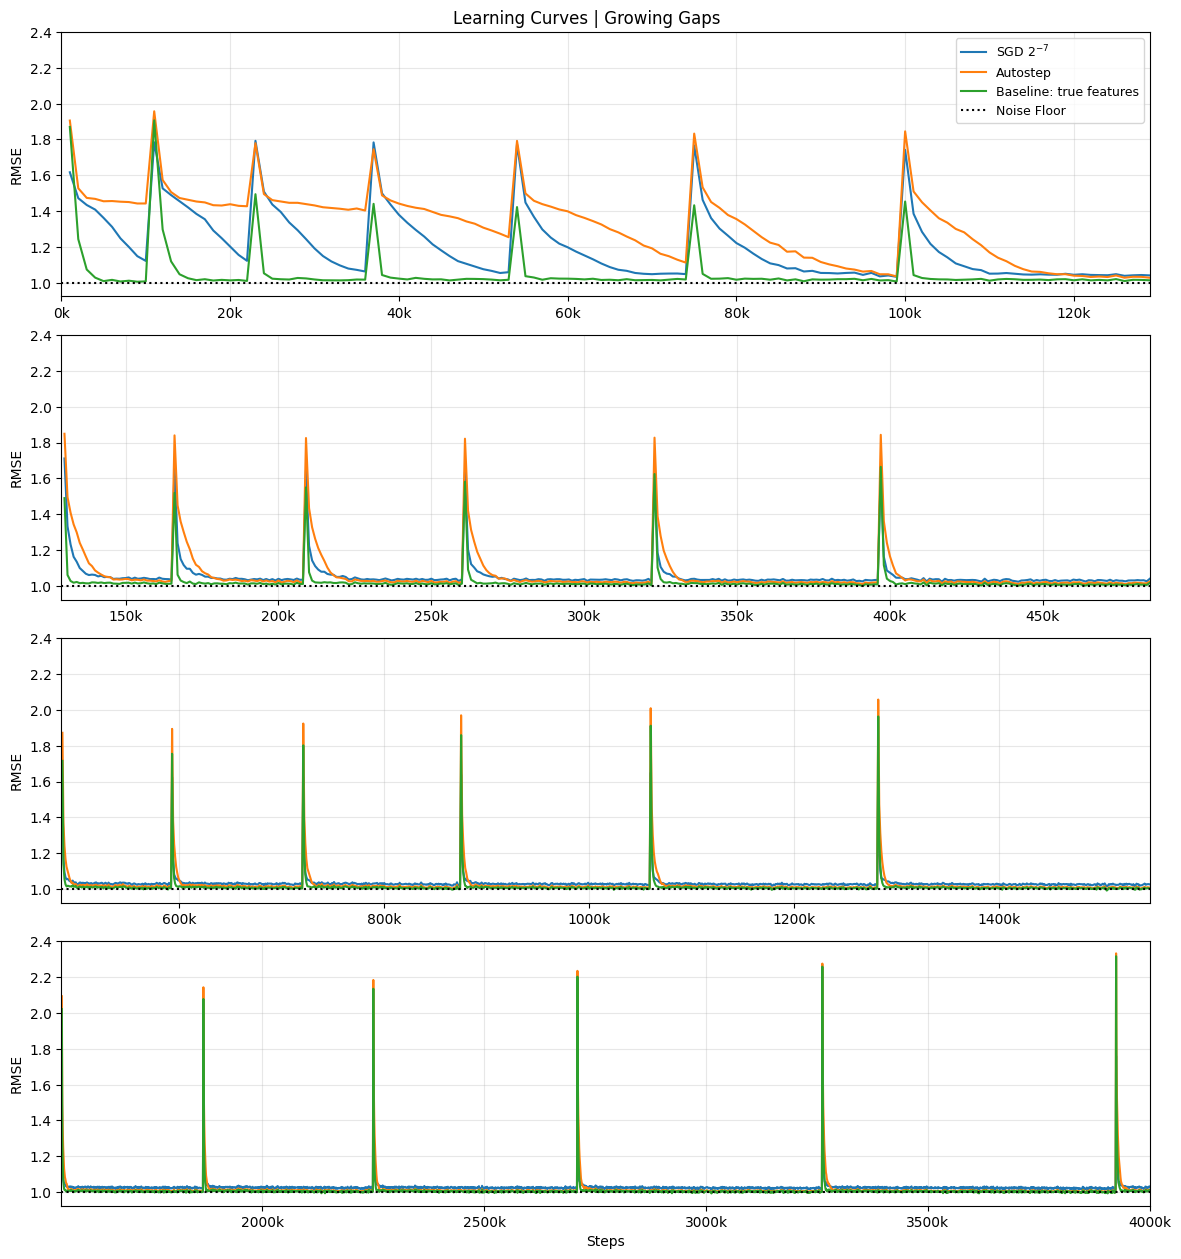

Comparison uses SGD 2^(-7), chosen by whole-run RMSE from the sweep.


In [14]:
x = np.arange(1, STEPS // WINDOW + 1) * WINDOW
sgd_labels = [rf'SGD $2^{{{p}}}$' for p in SGD_EXPONENTS]
best = int(np.argmin(np.sqrt(sgd.mean(axis=2)).mean(axis=1)))
curves = [(sgd_labels[best], sgd[best]), ('Autostep', autostep[0]), ('Baseline: true features', reference[0])]
ends = np.cumsum(turns) * WINDOW

# Four consecutive parts of the run, each about ten turns long.
parts = np.array_split(np.arange(len(turns)), 4)
fig, axes = plt.subplots(len(parts), 1, figsize=(12, 3.2 * len(parts)), sharey=True)
for ax, part in zip(axes, parts):
    left, right = (ends[part[0] - 1] if part[0] else 0), min(ends[part[-1]], STEPS)
    visible = (x > left) & (x <= right)
    for label, values in curves:
        ax.plot(x[visible], np.sqrt(values[:, visible]).mean(axis=0), label=label)
    ax.axhline(1., color='black', ls=':', label='Noise Floor')
    ax.set_xlim(left, right)
    ax.xaxis.set_major_formatter(lambda t, _: f'{t / 1000:g}k')
    ax.set_ylabel('RMSE')
    ax.grid(True, alpha=.3)
axes[0].legend(fontsize=9)
axes[-1].set_xlabel('Steps')
fig.suptitle('Learning Curves | Growing Gaps')
fig.tight_layout()
plt.show()
print(f'Comparison uses SGD 2^({SGD_EXPONENTS[best]}), chosen by whole-run RMSE from the sweep.')

All curves use five paired seeds; no uncertainty bands are shown.

**Result (73.6s on GPU):** SGD $2^{-7}$ has the lowest whole-run RMSE of the sweep. Over the first ~300k steps, SGD and Autostep are still learning the features and recover more slowly than the baseline after each switch. After that, all three recover within a few thousand steps of each switch. Between switches, Autostep and the baseline settle near the noise floor (last 50k: 1.009 and 1.005) and SGD a little above it (1.026). The first 1k steps after a switch get worse as turns lengthen for Autostep and the baseline (1.74 → 1.97 and 1.36 → 1.89 from turn 10 to the last turn), but not for SGD (1.67 → 1.61).